# 2 · The fractured granite: from one image log to a calibrated fracture-network ensemble

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE, Milford, Utah (USA)**

**Question.** What do we know about the fractures in the FORGE granitoid, and how much of it survives a test against the 2024 circulation between wells 16A(78)-32 and 16B(78)-32?

**Data** (all on the DOE Geothermal Data Repository, GDR, under CC BY 4.0; `data/` holds only derived values, rebuilt by `rebuild_data.py`):
* **58-32 FMI fracture picks** (GDR 1299): 147 fractures between 7,393 and 7,527 ft, with apparent (FVA) and hydraulic (FVAH) aperture. The file has no dip or azimuth.
* **Fracture orientations and sizes** from the FORGE 2024 reference discrete fracture network (DFN) of Finnila and Jones (GDR 1646, DOI [10.15121/2440870](https://doi.org/10.15121/2440870)): four natural sets, 17,798 fractures of 13–145 m radius, conditioned on the FORGE image logs.
* **The stimulated network**: the May 2024 connected DFN of the same submission: planes fitted to the 2024 microseismicity, hydraulic fractures at the 16A stages and natural fractures at the wells (120 fractures).
* **Well trajectories** of 16A(78)-32 and 16B(78)-32 (GDR 1646), checked against the well table of the extended circulation test report (GDR 1683).
* **Stress direction**: SHmax N25E (range N10E–N40E) from the FORGE stress summary of Finnila and Podgorney (2020, GDR 1222).

*Credit: Utah FORGE, U.S. Department of Energy, via the Geothermal Data Repository (OpenEI), CC BY 4.0.*

**Method.** The fractures are an **equivalent continuum**: every fracture adds its Oda (1985) permeability tensor, a³A(I − nn)/12V, to the cells it crosses. Natural fractures larger than the cell are placed one by one (Poisson discs, power-law sizes); smaller ones add their expected tensor. The stimulated network is placed as given. In-situ apertures are unknown, so one factor on the stimulated apertures is **calibrated** on the August 2024 test; everything else is checked, not fitted (notebook 3).

**Labels.** Every model number here is **simulated** by the KAI Reservoir Lab engine (`results/kai_engine_phase3.json`). This notebook recomputes the data-derived numbers with the MIT helpers in `forge_tools.py` and stops if they disagree with the engine.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import forge_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, GRANITE, BLUE, GREY = "#c9a227", "#26292e", "#b5838d", "#2a78d6", "#8a8f98"     # KAI energy palette
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)
E = json.loads(pathlib.Path("results/kai_engine_phase3.json").read_text())      # KAI engine run (simulated)
ens = E["ensemble"]
def pct(d, f="{:.1f}"):
    fm = lambda v: v if isinstance(v, str) else f.format(v)
    return f"{fm(d['P50'])} ({fm(d['P10'])}–{fm(d['P90'])})"
print(E["label"]); print(f"ensemble: {ens['members'] - ens['failed']}/{ens['members']} members ran, {ens['calibration_converged']} calibrated")

simulated (KAI Reservoir Lab TPFA solver, equivalent-continuum fractured granite); not field data
ensemble: 20/20 members ran, 20 calibrated


## What the image log says

Density along the hole (P10) is the count over the logged span. The apertures are skewed: a few wide fractures dominate any cubic-law permeability.

{
 "n": 147,
 "n_with_aperture": 123,
 "span_m": 40.259,
 "p10_per_m": 3.651,
 "aperture_mm_P10": 0.103,
 "aperture_mm_P50": 0.274,
 "aperture_mm_P90": 1.643,
 "aperture_mm_cubic_mean": 2.031
}
FVA (apparent) median 0.179 mm


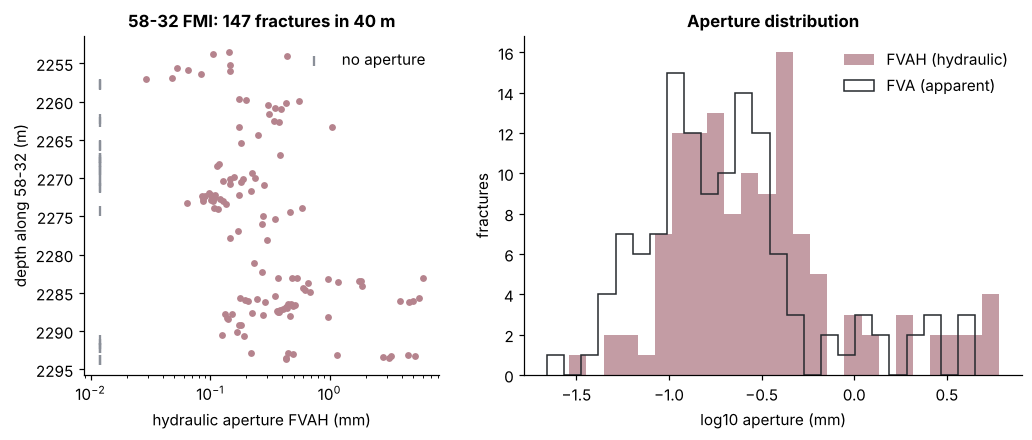

In [2]:
fmi = pd.read_csv("data/fmi_58_32.csv")
st = ft.fmi_stats(fmi.depth_m, fmi.fvah_mm); st_fva = ft.fmi_stats(fmi.depth_m, fmi.fva_mm)
for k in ("n", "n_with_aperture", "span_m", "p10_per_m"):
    assert abs(st[k] - E["fmi"][k]) <= 1e-4 * abs(E["fmi"][k]), k            # depths are stored to the mm
assert abs(st["aperture_mm_P50"] - E["fmi"]["aperture_m"]["P50"] * 1e3) < 1e-4     # apertures stored to 0.01 µm
print(json.dumps({k: round(v, 3) for k, v in st.items()}, indent=1))
print("FVA (apparent) median", round(st_fva["aperture_mm_P50"], 3), "mm")
fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.4]})
ok = fmi.fvah_mm > 0
ax[0].scatter(fmi.fvah_mm[ok], fmi.depth_m[ok], s=12, color=GRANITE); ax[0].scatter(np.full((~ok).sum(), 0.012), fmi.depth_m[~ok], marker="|", color=GREY, label="no aperture")
ax[0].set_xscale("log"); ax[0].invert_yaxis(); ax[0].set_xlabel("hydraulic aperture FVAH (mm)"); ax[0].set_ylabel("depth along 58-32 (m)"); ax[0].legend()
ax[0].set_title(f"58-32 FMI: {st['n']} fractures in {st['span_m']:.0f} m")
ax[1].hist(np.log10(fmi.fvah_mm[ok]), bins=25, color=GRANITE, alpha=0.8, label="FVAH (hydraulic)")
ax[1].hist(np.log10(fmi.fva_mm[fmi.fva_mm > 0]), bins=25, histtype="step", color=CHARCOAL, label="FVA (apparent)")
ax[1].set_xlabel("log10 aperture (mm)"); ax[1].set_ylabel("fractures"); ax[1].legend(); ax[1].set_title("Aperture distribution")
fig.savefig("figures/forge_fmi_58_32.png")

## Orientations: the 2024 reference DFN

The FMI file has no orientations, so they come from the four natural sets of the FORGE reference DFN (GDR 1646). A vertical hole under-samples steep fractures; the Terzaghi correction P32 = P10 / E[|cos θ|] turns the count along 58-32 into fracture area per rock volume.

,set,fractures,area share,pole trend/plunge (°),engine,median radius (m)
0,Set 1 Dipping South,6334,0.351,358 / 12,358 / 12,24.7
1,Set 2 Striking SSW,6293,0.350,115 / 3,115 / 3,24.6
2,Set 3 Dipping West,3554,0.200,75 / 35,75 / 35,24.8
3,Set 4 Dipping East,1617,0.099,229 / 50,229 / 50,25.1


Terzaghi: E[|cos|] = 0.336  ->  P32 = 10.87 m²/m³ (P10 3.65 /m)


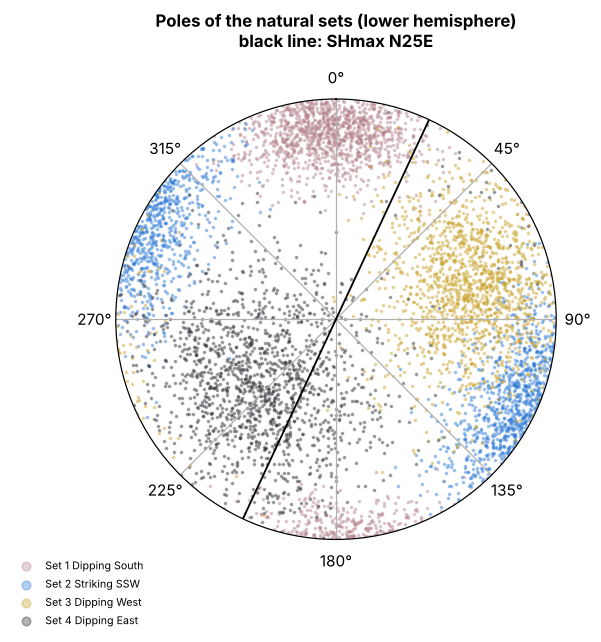

In [3]:
poles = pd.read_csv("data/natural_fracture_poles.csv")
n = ft.pole(poles.trend, poles.plunge); A = np.pi * poles.radius_m**2
p32, mcos = ft.terzaghi_p32(st["p10_per_m"], n, A)
rows = []
for s, g in poles.groupby("set"):
    nn = ft.pole(g.trend, g.plunge); w = np.pi * g.radius_m**2
    T = (nn * w.values[:, None]).T @ nn / w.sum(); ev, vec = np.linalg.eigh(T); m = vec[:, -1] * np.sign(-vec[2, -1] or 1)
    tr, pl = np.degrees(np.arctan2(m[0], m[1])) % 360, np.degrees(np.arcsin(abs(m[2])))
    es = E["natural_sets"][s]
    rows.append({"set": s, "fractures": len(g), "area share": round(w.sum() / A.sum(), 3), "pole trend/plunge (°)": f"{tr:.0f} / {pl:.0f}",
                 "engine": f"{es['trend_deg']:.0f} / {es['plunge_deg']:.0f}", "median radius (m)": round(g.radius_m.median(), 1)})
    assert abs(w.sum() / A.sum() - es["area_share"]) < 1e-3
display(pd.DataFrame(rows))
member = E["members"][0]
print(f"Terzaghi: E[|cos|] = {mcos:.3f}  ->  P32 = {p32:.2f} m²/m³ (P10 {st['p10_per_m']:.2f} /m)")
fig = plt.figure(figsize=(5.2, 5.2)); ax = fig.add_subplot(projection="polar")
cols = dict(zip(sorted(poles.set.unique()), [GRANITE, BLUE, GOLD, CHARCOAL]))
for s, g in poles.groupby("set"):
    sub = g.sample(min(len(g), 1500), random_state=0)
    r = np.sqrt(2) * np.sin(np.radians(90 - sub.plunge) / 2)                       # Lambert equal area, lower hemisphere
    ax.scatter(np.radians(sub.trend), r, s=2, color=cols[s], alpha=0.35, label=s)
for az in (25, 205):
    ax.plot([np.radians(az)] * 2, [0, 1], color="k", lw=1.2)
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_rticks([]); ax.set_ylim(0, 1)
ax.set_title("Poles of the natural sets (lower hemisphere)\nblack line: SHmax N25E", pad=14); ax.legend(loc="lower left", bbox_to_anchor=(-0.25, -0.22), fontsize=7, markerscale=4)
fig.savefig("figures/forge_fracture_poles.png")

## Taken at face value, the FMI apertures fail the circulation test

If the FMI hydraulic apertures were the in-situ apertures, the Oda tensor of this network would make the granitoid about as permeable as gravel. The circulation test says otherwise: in August 2024 it took about 21 MPa between the wells to move 26 kg/s.

In [4]:
ap = fmi.fvah_mm[ok].values * 1e-3
k_face = ft.oda_homogeneous(p32, n, A, ap)
pc = E["prior_check"]["FMI and GDR 1646 apertures as published"]
print("Oda k with FMI apertures (east, north, vertical):", np.array2string(k_face, precision=2), "m²")
print(f"engine, 35 m cells, same apertures: median {np.mean(pc['k_natural_median_m2']):.2e} m²")
assert 0.3 < np.mean(k_face) / np.mean(pc["k_natural_median_m2"]) < 3
print(f"inter-well impedance: model {pc['impedance_model_mpa_per_kg_s']:.3f} vs measured {pc['impedance_measured_mpa_per_kg_s']:.2f} MPa per kg/s "
      f"({pc['impedance_measured_mpa_per_kg_s'] / pc['impedance_model_mpa_per_kg_s']:.0f} × too easy)")

Oda k with FMI apertures (east, north, vertical): [4.50e-09 4.34e-09 6.32e-09] m²
engine, 35 m cells, same apertures: median 4.98e-09 m²
inter-well impedance: model 0.011 vs measured 0.79 MPa per kg/s (72 × too easy)


## The wells and the stimulated network

The trajectories (GDR 1646) are checked against the well table of the extended-circulation report (GDR 1683): well heads, kick-off, tangent azimuth, total depth and true vertical depth at the toe. Both wells start on the pad the 2021 survey lists as "16A-32"; "78B-32" is a different well about 1.3 km away.

,well,TVD at report TD (ft): trajectory / report,tangent azimuth (°),inclination (°),kick-off (ft)
0,16A(78)-32,8561 / 8540,109.3 / 105,64.5,5878 / 5938
1,16B(78)-32,8294 / 8262,103.2 / 105,64.6,5518 / 5600


16B head: trajectory vs report 0.0 m; 16A head 8.6 m; open intervals 90–108 m apart (median 96 m)


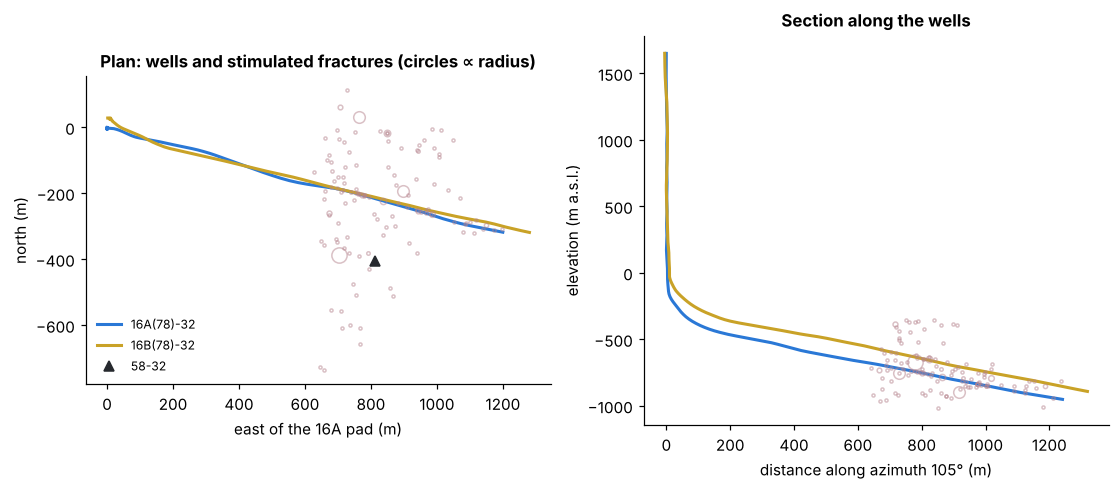

In [5]:
wh = E["wellheads"]
tab = []
for w in ("16A(78)-32", "16B(78)-32"):
    d = wh[w]
    tab.append({"well": w, "TVD at report TD (ft): trajectory / report": f"{d['tvd_at_report_md_ft']:.0f} / {d['report_tvd_toe_ft']:.0f}",
                "tangent azimuth (°)": f"{d['tangent_azimuth_deg']:.1f} / {d['report_azimuth_deg']}", "inclination (°)": round(d["tangent_inclination_deg"], 1),
                "kick-off (ft)": f"{d['kick_off_ft']:.0f} / {d['report_kop_ft']}"})
    assert abs(d["tvd_at_report_md_ft"] - d["report_tvd_toe_ft"]) < 50 and abs(d["tangent_azimuth_deg"] - d["report_azimuth_deg"]) < 6
display(pd.DataFrame(tab))
print(f"16B head: trajectory vs report {wh['16B_head_traj_vs_report_m']:.1f} m; 16A head {wh['16A_head_traj_vs_report_m']:.1f} m; "
      f"open intervals {wh['open_interval_separation_m']['min']:.0f}–{wh['open_interval_separation_m']['max']:.0f} m apart (median {wh['open_interval_separation_m']['median']:.0f} m)")
tr = pd.read_csv("data/trajectories_16A_16B.csv"); sd = pd.read_csv("data/stimulated_dfn.csv"); wl = pd.read_csv("data/wells.csv").set_index("well")
a = np.radians(105); ux, uy = np.sin(a), np.cos(a)
E0, N0 = 334640.0, 4263443.0
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for w, g in tr.groupby("well"):
    s_ = (g.easting - E0) * ux + (g.northing - N0) * uy
    c = BLUE if w.startswith("16A") else GOLD
    ax[0].plot(g.easting - E0, g.northing - N0, color=c, lw=2, label=w); ax[1].plot(s_, g.elev_m, color=c, lw=2, label=w)
sn = ft.pole(sd.trend, sd.plunge)
for _, r in sd.iterrows():
    e = ((r.easting - E0) * ux + (r.northing - N0) * uy)
    ax[0].plot(r.easting - E0, r.northing - N0, "o", ms=max(2, r.radius_m / 40), mfc="none", color=GRANITE, alpha=0.5)
    ax[1].plot(e, r.elev_m, "o", ms=max(2, r.radius_m / 40), mfc="none", color=GRANITE, alpha=0.5)
ax[0].plot(wl.loc["58-32"].easting - E0, wl.loc["58-32"].northing - N0, "^", color=CHARCOAL, label="58-32")
ax[0].set_aspect("equal"); ax[0].set_xlabel("east of the 16A pad (m)"); ax[0].set_ylabel("north (m)"); ax[0].legend(fontsize=8); ax[0].set_title("Plan: wells and stimulated fractures (circles ∝ radius)")
ax[1].set_xlabel("distance along azimuth 105° (m)"); ax[1].set_ylabel("elevation (m a.s.l.)"); ax[1].set_title("Section along the wells")
fig.savefig("figures/forge_wells_stimulated_dfn.png")

## The ensemble

Four inputs are uncertain. Each member samples them (Latin hypercube) and then calibrates one number, the factor λ on the stimulated apertures, so that the model's injection pressure after 20 days at 10 bpm matches the August 2024 test.

| Input | Distribution | Why |
|---|---|---|
| P10 of natural fractures | log-normal, median = the 58-32 count, P10–P90 ×/÷ 1.35 | one 40 m log stands for the whole reservoir |
| Natural aperture factor (in situ / FMI) | log-uniform 0.0003–0.003 | FMI apertures are measured at the borehole wall; the test rules out values near 1 |
| Rotation of the natural sets | triangular −15°, 0, +15° | SHmax N10E–N40E around N25E (GDR 1222) |
| Spread of the stimulated apertures | uniform 0–1 (log-normal σ, fracture by fracture) | which stimulated fractures carry the flow |

P10 is the 10th percentile of the members (the low case), P90 the 90th.

In [6]:
inp = ens["inputs"]
labels = {"p10_per_m": ("natural P10 (1/m)", "{:.2f}"), "p32_per_m": ("natural P32 (m²/m³)", "{:.1f}"),
          "bg_aperture_factor": ("natural aperture factor", "{:.5f}"), "k_natural_median_m2": ("natural-network k (m²)", "{:.1e}"),
          "rotation_deg": ("rotation of the sets (°)", "{:.1f}"), "stim_aperture_sigma": ("stimulated aperture spread σ", "{:.2f}"),
          "stim_aperture_factor_calibrated": ("calibrated stimulated aperture factor λ", "{:.3f}")}
display(pd.DataFrame([{"input": l, "P50 (P10–P90)": pct(inp[k], f)} for k, (l, f) in labels.items()]))
m0 = E["median_member"]
print(f"median member: λ = {m0['calibration']['stim_aperture_factor']:.3f} after {m0['calibration']['iterations']} runs; "
      f"Δp target {m0['calibration']['dp_target_pa'] / 1e6:.1f} MPa")
diag = E["members"][0]["model"]
print(f"Oda off-diagonal terms (dropped by the TPFA solver): up to {diag['off_diagonal_max_natural']:.2f} of the diagonal for the natural network, "
      f"90th percentile {diag['off_diagonal_p90_stimulated']:.2f} for the stimulated one")

,input,P50 (P10–P90)
0,natural P10 (1/m),3.67 (2.75–4.72)
1,natural P32 (m²/m³),10.9 (8.2–14.0)
2,natural aperture factor,0.00093 (0.00041–0.00234)
3,natural-network k (m²),3.4e-18 (4.0e-19–7.3e-17)
4,rotation of the sets (°),0.1 (-7.3–7.4)
5,stimulated aperture spread σ,0.50 (0.11–0.90)
6,calibrated stimulated aperture factor λ,0.131 (0.064–0.154)


median member: λ = 0.150 after 3 runs; Δp target 20.9 MPa
Oda off-diagonal terms (dropped by the TPFA solver): up to 0.33 of the diagonal for the natural network, 90th percentile 0.42 for the stimulated one


## Published numbers

The numbers quoted in the README and on the case page. The notebook stops if they change.

In [7]:
published = {"p10_per_m": 3.651, "aperture_mm_P50": 0.2737, "p32_per_m": 10.87, "impedance_ratio": 71.65, "lambda_P10": 0.06391, "lambda_P50": 0.1306, "lambda_P90": 0.1538}
now = {"p10_per_m": st["p10_per_m"], "aperture_mm_P50": st["aperture_mm_P50"], "p32_per_m": p32,
       "impedance_ratio": pc["impedance_measured_mpa_per_kg_s"] / pc["impedance_model_mpa_per_kg_s"],
       "lambda_P50": inp["stim_aperture_factor_calibrated"]["P50"], "lambda_P10": inp["stim_aperture_factor_calibrated"]["P10"],
       "lambda_P90": inp["stim_aperture_factor_calibrated"]["P90"]}
for k, v in published.items():
    assert abs(now[k] - v) <= 0.02 * abs(v) + 1e-3, (k, now[k], v)
pathlib.Path("results/nb2_fractured_granite.json").write_text(json.dumps({"fmi": st, "terzaghi_mean_abs_cos": mcos, "p32_per_m": p32,
    "oda_k_fmi_apertures_m2": k_face.tolist(), "published": now}, indent=1))
print("all published numbers reproduced")

all published numbers reproduced


## What this gives the Reservoir Lab, and its limits

* The 58-32 image log gives **3.65 fractures per metre** along the hole; with the reference-DFN orientations that is about **11 m² of fracture per m³** of granitoid.
* Taken as in-situ hydraulic apertures, the FMI apertures would make the well pair about **70 times** easier to circulate than the August 2024 test shows. In-situ apertures are much smaller than those seen at the borehole wall.
* The calibrated ensemble needs the stimulated fractures at about **an eighth** of the apertures assumed in the 2024 DFN (see the table). The rest of the ensemble spread comes from density, orientation and which stimulated fractures carry the flow.

**Limits.** Equivalent continuum: one permeability tensor per 35 m cell; the solver keeps its diagonal (off-diagonal terms are reported above). Oda's tensor assumes the fractures are connected, which holds for this dense network. Apertures do not change with pressure or temperature in the model, although the test injected near the minimum horizontal stress. Heat moves between water and rock in the same cell at once; at 0.28 m mean fracture spacing the rock blocks equilibrate in hours, so this holds for the natural network but may overstate heat sweep if flow is channelled into a few fractures.

*References:* Blochowicz, A. (2021). Utah FORGE: Well 58-32 FMI Log Fracture Results. GDR 1299 · Finnila, A. and Jones, C. (2024). Utah FORGE: 2024 Discrete Fracture Network Model Data. GDR 1646, DOI 10.15121/2440870 · Finnila, A. and Podgorney, R. (2020). Utah FORGE: Discrete Fracture Network (DFN) Data. GDR 1222 · McLennan, J., England, K. and Swearingen, L. (2024). Extended Circulation Test Data. GDR 1683, DOI 10.15121/2475065 · Oda, M. (1985). Permeability tensor for discontinuous rock masses. Géotechnique 35(4) · Terzaghi, R. (1965). Sources of error in joint surveys. Géotechnique 15(3).